# Telecommunications Customer Churn Prediction

## 1. Introduction

Customer churn occurs when a customer stops using a
company's products or services. High customer churn
can negatively affect a telecommunications company's
revenue and business growth.

The aim of this project is to develop a machine-learning
classification system that predicts whether a
telecommunications customer is likely to leave the
company based on historical customer information.

The project uses IBM's Telco Customer Churn dataset.

Logistic Regression will be used as the baseline model,
while Random Forest will be trained as an alternative
model for comparison.

In [ ]:
# Importing libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries will be added
# when we reach the preprocessing and modelling stages.

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Loading the dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0


In [ ]:
print("Target variable: Churn")

print(df["Churn"].value_counts())

Target variable: Churn
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate customer IDs: 0


In [ ]:
# Check for blank or whitespace-only TotalCharges entries

blank_totalcharges = df["TotalCharges"].astype(str).str.strip().eq("").sum()

print("Blank TotalCharges entries:", blank_totalcharges)

Blank TotalCharges entries: 11


In [ ]:
# Display records with blank TotalCharges

df[df["TotalCharges"].astype(str).str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
# Remove whitespace from TotalCharges

df["TotalCharges"] = df["TotalCharges"].str.strip()

# Convert TotalCharges to numerical values

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values again

print(df["TotalCharges"].isnull().sum())

11


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nBlank TotalCharges entries:")
print(df["TotalCharges"].astype(str).str.strip().eq("").sum())

Missing values after cleaning:
0

TotalCharges data type:
float64

Blank TotalCharges entries:
0


In [ ]:
# Check numerical columns for invalid values

print("Negative tenure:", (df["tenure"] < 0).sum())

print("Negative MonthlyCharges:",
      (df["MonthlyCharges"] < 0).sum())

print("Negative TotalCharges:",
      (df["TotalCharges"] < 0).sum())

print("Invalid SeniorCitizen values:",
      (~df["SeniorCitizen"].isin([0, 1])).sum())

print("Invalid Churn values:",
      (~df["Churn"].isin(["Yes", "No"])).sum())

Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0
Invalid SeniorCitizen values: 0
Invalid Churn values: 0


In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### Data Cleaning and Preparation

The dataset was examined for duplicate records,
missing values and invalid entries.

No duplicate rows or duplicate customer IDs were found.

Although the initial missing-value check showed no
missing values, further investigation revealed 11
blank entries in the TotalCharges column.

All 11 records had a tenure of zero months. These
blank entries were converted to numerical missing
values and subsequently replaced with zero because
the customers had no recorded accumulated charges.

The TotalCharges column was converted from an object
data type to a numerical data type.

Additional checks were performed to identify negative
values in numerical columns and invalid categories
in the target and SeniorCitizen columns.

## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand
the distribution of customer churn and investigate
relationships between customer characteristics and
churn behaviour.

Visualizations and statistical summaries are used
to identify patterns that may help explain customer
churn.

In [ ]:
# Calculate the number of customers in each churn category

print(df["Churn"].value_counts())

# Calculate the percentage of customers in each category

print("\nChurn Percentage:")

print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


The analysis shows that 5,174 customers (73.46%)
did not churn, while 1,869 customers (26.54%)
churned.

This indicates that although most customers remained
with the telecommunications company, approximately
one-quarter of the customers discontinued their
services.

The target variable is imbalanced because the number
of customers who did not churn is significantly higher
than those who churned. This will be considered when
evaluating the machine-learning models.

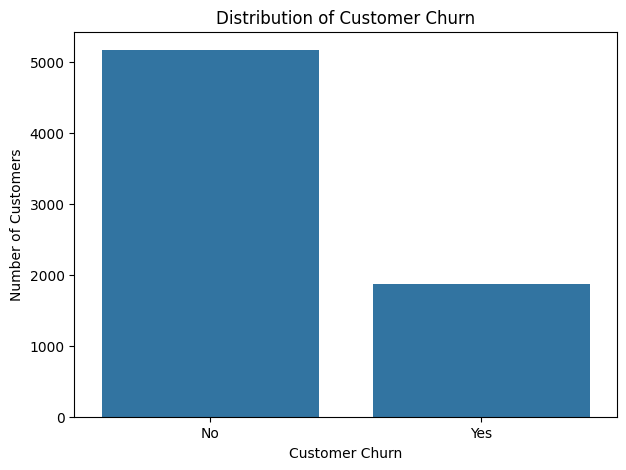

In [ ]:
# Visualizing customer churn distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

The analysis shows that 5,174 customers (73.46%)
did not churn, while 1,869 customers (26.54%)
churned.

This indicates that although most customers remained
with the telecommunications company, approximately
one-quarter of the customers discontinued their
services.

The target variable is imbalanced because the number
of customers who did not churn is significantly higher
than those who churned. This will be considered when
evaluating the machine-learning models.

In [ ]:
# Calculate churn rate for each contract type

contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


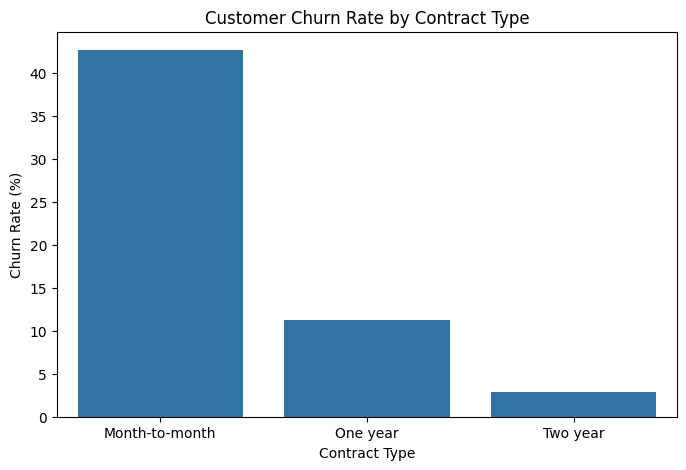

In [ ]:
# Visualizing churn rate by contract type

plt.figure(figsize=(8, 5))

sns.barplot(x=contract_churn.index, y=contract_churn.values)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

The visualization shows a relationship between
contract type and customer churn.

Customers on month-to-month contracts have a
considerably higher churn rate compared to customers
on one-year and two-year contracts.

Customers with longer-term contracts appear less
likely to churn.

This suggests that contract type is an important
feature to investigate when predicting customer churn.

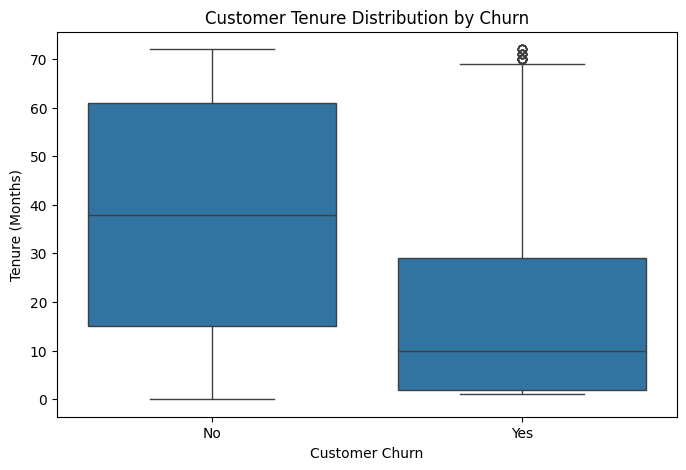

In [ ]:
# Visualizing customer tenure against churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

The boxplot shows differences in customer tenure
between customers who churned and those who remained.

Customers who churned generally had shorter tenures,
while customers who did not churn tended to have
longer relationships with the company.

This suggests that newer customers may be more
vulnerable to churn than long-term customers.

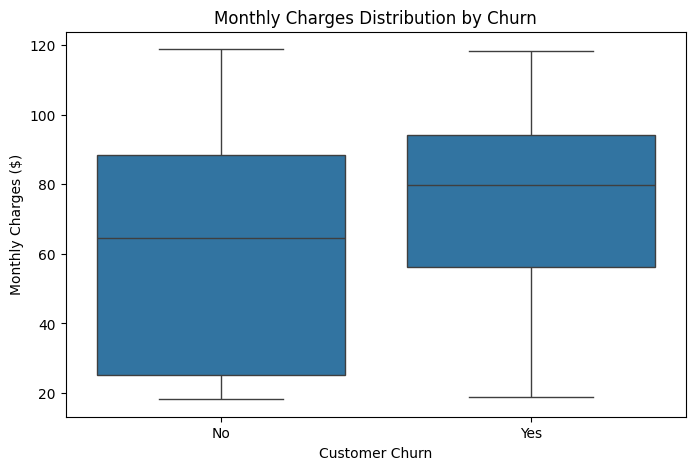

In [ ]:
# Visualizing monthly charges against churn

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")

plt.show()

The boxplot indicates that customers who churned
generally had higher monthly charges than customers
who remained with the company.

This suggests an association between monthly charges
and customer churn.

However, the visualization does not establish that
higher monthly charges directly cause customers to
leave the company.

In [ ]:
# Calculate churn rate by contract type

contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Contract Type:")
print(contract_churn)

Churn Rate by Contract Type:
Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


### Churn Rate by Contract Type

The analysis shows significant differences in churn
rates across contract categories.

Month-to-month contracts recorded the highest churn
rate of 42.71%, followed by one-year contracts at
11.27%. Two-year contracts had the lowest churn rate
of 2.83%.

This indicates a strong association between contract
type and customer churn. Customers on month-to-month
contracts appear considerably more likely to leave
than customers on longer-term contracts.

Contract type may therefore be an important feature
for predicting customer churn.

In [ ]:
# Compare tenure between churn groups

print(df.groupby("Churn")["tenure"].agg(
    ["mean", "median"]
))

            mean  median
Churn                   
No     37.569965    38.0
Yes    17.979133    10.0


### Customer Tenure and Churn

The numerical analysis shows that customers who
churned had an average tenure of approximately
17.98 months and a median tenure of 10 months.

In comparison, customers who did not churn had an
average tenure of 37.57 months and a median tenure
of 38 months.

This indicates that customers who leave generally
have shorter relationships with the company than
those who remain.

The findings suggest that customer tenure is an
important variable to investigate when predicting
churn.

In [ ]:
# Compare monthly charges between churn groups

print(df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
))

            mean  median
Churn                   
No     61.265124  64.425
Yes    74.441332  79.650


### Monthly Charges and Churn

The analysis shows that customers who churned had
higher monthly charges than customers who remained.

Customers who churned recorded an average monthly
charge of $74.44 and a median of $79.65.

In comparison, customers who did not churn had an
average monthly charge of $61.27 and a median of
$64.43.

This suggests an association between higher monthly
charges and customer churn. However, this relationship
does not establish that higher charges directly cause
customers to leave.

### Overall EDA Findings

The exploratory data analysis revealed several
patterns associated with customer churn.

1. Approximately 26.54% of customers churned, while
   73.46% remained with the company.

2. Month-to-month contract customers recorded the
   highest churn rate of 42.71%, compared to 11.27%
   for one-year contracts and 2.83% for two-year
   contracts.

3. Customers who churned had a lower median tenure
   of 10 months compared to 38 months for customers
   who remained.

4. Customers who churned also had higher average
   monthly charges ($74.44) than customers who stayed
   ($61.27).

These findings suggest that contract type, customer
tenure and monthly charges are useful variables to
investigate when developing a customer churn
prediction model.

However, these relationships represent associations
within the dataset and do not establish causation.

## 7. Data Preprocessing

Data preprocessing involves preparing the dataset
for machine-learning algorithms.

The target variable is separated from the input
features, and customer IDs are excluded because
they are unique identifiers rather than meaningful
predictive characteristics.

In [ ]:
# Separate input features and target variable

X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"]

In [ ]:
print("Input features shape:", X.shape)

print("Target variable shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features shape: (7043, 19)
Target variable shape: (7043,)

Input features:
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          N

In [ ]:
# Identify numerical and categorical features

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:",
      len(numerical_features))

print("Number of categorical features:",
      len(categorical_features))

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 16


In [ ]:
# Convert target variable into binary values

y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)


In [ ]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
# Numerical preprocessing

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

In [ ]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer, numerical_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

In [ ]:
# Fit preprocessing on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessing

X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Training data shape:", X_train_processed.shape)

print("Testing data shape:", X_test_processed.shape)

print("\nTraining target shape:", y_train.shape)

print("Testing target shape:", y_test.shape)

Training data shape: (5634, 30)
Testing data shape: (1409, 30)

Training target shape: (5634,)
Testing target shape: (1409,)


In [ ]:
import numpy as np

print("Missing values in training:",
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed).sum())

Missing values in training: 0
Missing values in testing: 0


## 8. Logistic Regression Model

Logistic Regression is used as the baseline
classification algorithm for predicting customer
churn.

The model learns relationships between customer
features and the binary churn target variable.

In [ ]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

In [ ]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [ ]:
# Train Logistic Regression model

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict customer churn

y_pred_logistic = logistic_model.predict(X_test)

print("First 20 predictions:")
print(y_pred_logistic[:20])

First 20 predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [ ]:
# Obtain churn probabilities

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 churn probabilities:")
print(y_prob_logistic[:10])

First 10 churn probabilities:
[0.0464133  0.68419325 0.0603014  0.39859274 0.02183171 0.60351226
 0.44587604 0.12874292 0.00290068 0.39573055]


In [ ]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [ ]:
accuracy = accuracy_score(y_test, y_pred_logistic)

print("Accuracy:", accuracy)

Accuracy: 0.8062455642299503


In [ ]:
precision = precision_score(y_test, y_pred_logistic)

print("Precision:", precision)

Precision: 0.6593059936908517


In [ ]:
recall = recall_score(y_test, y_pred_logistic)

print("Recall:", recall)

Recall: 0.5588235294117647


In [ ]:
f1 = f1_score(y_test, y_pred_logistic)

print("F1 Score:", f1)

F1 Score: 0.6049204052098408


In [ ]:
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8421710713270816


In [ ]:
# Logistic Regression evaluation results

logistic_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print(logistic_results)

      Metric     Score
0   Accuracy  0.806246
1  Precision  0.659306
2     Recall  0.558824
3   F1 Score  0.604920
4    ROC-AUC  0.842171


In [ ]:
# Generate confusion matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

print("Confusion Matrix:")
print(cm_logistic)

Confusion Matrix:
[[927 108]
 [165 209]]


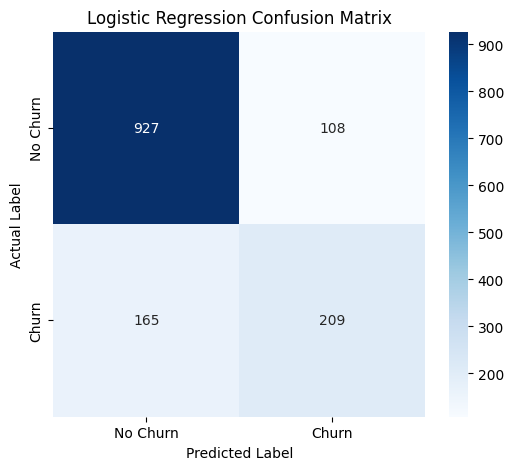

In [ ]:
# Visualize confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Interpretation of Logistic Regression Results

The Logistic Regression model achieved an accuracy of **80.62%**, precision of **65.93%**, recall of **55.88%**, F1 score of **60.49%**, and ROC-AUC of **84.22%**.

The model correctly classified 927 customers who did not churn and 209 customers who churned. However, it incorrectly classified 108 customers as potential churners when they actually stayed, and failed to identify 165 customers who actually churned.

The recall score of 55.88% indicates that the model identified approximately 56% of actual churn cases. This suggests that the model still misses a considerable number of customers who may leave the company.

Although the model achieved a reasonably good accuracy and ROC-AUC score, its ability to identify customers who churn needs improvement. Since identifying potential churners is important for customer retention, improving recall while maintaining reasonable precision should be considered when comparing models.

Overall, Logistic Regression provides a useful baseline for the customer churn prediction task.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

In [ ]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [ ]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [ ]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("----------------------")
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)
print("ROC-AUC:", roc_auc_rf)

Random Forest Results
----------------------
Accuracy: 0.7913413768630234
Precision: 0.6388888888888888
Recall: 0.4919786096256685
F1 Score: 0.5558912386706949
ROC-AUC: 0.8237012064377793


In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[931 104]
 [190 184]]


In [ ]:
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### Interpretation of Random Forest Results

The Random Forest model achieved an accuracy of **79.13%**, precision of **63.89%**, recall of **49.20%**, F1 score of **55.59%**, and ROC-AUC of **82.37%**.

The confusion matrix shows that the model correctly identified 931 customers who did not churn and 184 customers who churned. However, it incorrectly predicted that 104 customers would churn when they actually stayed and failed to identify 190 customers who actually churned.

The recall score of 49.20% indicates that the model identified approximately half of the actual churn cases. This is a limitation because identifying customers who are likely to leave is an important objective of customer churn prediction.

When compared with Logistic Regression, Random Forest achieved lower scores across all five evaluation metrics. Therefore, based on this initial test-set evaluation, Logistic Regression performed better than Random Forest.

However, further model validation using cross-validation on the training data is necessary before making a final model selection.

In [ ]:
from sklearn.model_selection import cross_validate

# Define the evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Cross-validation for Logistic Regression
logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

# Cross-validation for Random Forest
rf_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

In [ ]:
import pandas as pd

cv_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        logistic_cv["test_accuracy"].mean(),
        logistic_cv["test_precision"].mean(),
        logistic_cv["test_recall"].mean(),
        logistic_cv["test_f1"].mean(),
        logistic_cv["test_roc_auc"].mean()
    ],
    "Random Forest": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean()
    ]
})

cv_results

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.804222,0.786118
1,Precision,0.657884,0.630981
2,Recall,0.547826,0.469565
3,F1 Score,0.597668,0.538007
4,ROC-AUC,0.845660,0.825288


### Interpretation of Cross-Validation Results

Five-fold cross-validation was performed to compare the performance of Logistic Regression and Random Forest using the training data.

The results show that Logistic Regression achieved higher average scores across all five evaluation metrics: accuracy (80.42%), precision (65.79%), recall (54.78%), F1 score (59.77%), and ROC-AUC (84.57%).

Random Forest achieved lower scores, with accuracy of 78.61%, precision of 63.10%, recall of 46.96%, F1 score of 53.80%, and ROC-AUC of 82.53%.

These results suggest that Logistic Regression performs better than Random Forest for this customer churn prediction task. In particular, Logistic Regression has a higher recall and F1 score, indicating that it identifies more actual churn cases and provides a better balance between precision and recall.

Therefore, Logistic Regression is the preferred model based on the current cross-validation results.

In [ ]:
# Get the preprocessing step from the trained Logistic Regression pipeline
fitted_preprocessor = logistic_model.named_steps["preprocessor"]

# Retrieve the names of the transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Display the feature names
print("Number of transformed features:", len(feature_names))

print("\nFeature names:")
print(feature_names)

Number of transformed features: 30

Feature names:
['numerical__tenure' 'numerical__MonthlyCharges' 'numerical__TotalCharges'
 'categorical__gender_Male' 'categorical__SeniorCitizen_1'
 'categorical__Partner_Yes' 'categorical__Dependents_Yes'
 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes'
 'categorical__StreamingTV_No internet service'
 'categorical__StreamingTV_Yes'
 'categorical__StreamingMovies_No internet service'
 'categorical__StreamingMovies_Yes' 'categorical__Contract_One year'
 'categorical__Contract_T

In [ ]:
import pandas as pd

# Extract coefficients from the trained Logistic Regression model
coefficients = logistic_model.named_steps["classifier"].coef_[0]

# Create a DataFrame containing feature names and coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort features by coefficient, from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

# Display the results
feature_importance

,Feature,Coefficient
10,categorical__InternetService_Fiber optic,1.180666
2,numerical__TotalCharges,0.527772
28,categorical__PaymentMethod_Electronic check,0.392775
21,categorical__StreamingTV_Yes,0.374831
26,categorical__PaperlessBilling_Yes,0.374218
23,categorical__StreamingMovies_Yes,0.373193
9,categorical__MultipleLines_Yes,0.361646
4,categorical__SeniorCitizen_1,0.147911
29,categorical__PaymentMethod_Mailed check,0.081866
17,categorical__DeviceProtection_Yes,0.033106


### Interpretation of Logistic Regression Coefficients

The Logistic Regression coefficients were examined to identify features associated with customer churn predictions.

The strongest positive coefficient was observed for Fiber optic internet (1.1807), suggesting that customers using this service had higher predicted odds of churn compared with the reference internet-service category. Other features associated with higher predicted churn included TotalCharges (0.5278), Electronic check payment (0.3928), StreamingTV (0.3748), and PaperlessBilling (0.3742).

The strongest negative coefficients were observed for two-year contracts (-1.3138) and customer tenure (-1.2571). This suggests that customers with longer-term contracts and longer relationships with the company had lower predicted odds of churn. One-year contracts (-0.6839), OnlineSecurity (-0.3491), and TechSupport (-0.2993) were also associated with lower predicted churn.

An interesting finding was that MonthlyCharges had a negative coefficient (-0.4665), despite the earlier exploratory analysis showing higher monthly charges among customers who churned. This may be due to relationships between monthly charges and other features included in the model.

Overall, contract type, tenure, and internet service were among the most influential features in the Logistic Regression model. These findings describe associations in the model and do not establish that the features directly cause customers to churn.

In [ ]:
import numpy as np

# Calculate odds ratios
feature_importance["Odds_Ratio"] = np.exp(
    feature_importance["Coefficient"]
)

# Sort by odds ratio, from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Odds_Ratio",
    ascending=False
)

# Display the results
feature_importance

,Feature,Coefficient,Odds_Ratio
10,categorical__InternetService_Fiber optic,1.180666,3.256541
2,numerical__TotalCharges,0.527772,1.695151
28,categorical__PaymentMethod_Electronic check,0.392775,1.481085
21,categorical__StreamingTV_Yes,0.374831,1.454745
26,categorical__PaperlessBilling_Yes,0.374218,1.453853
23,categorical__StreamingMovies_Yes,0.373193,1.452365
9,categorical__MultipleLines_Yes,0.361646,1.435691
4,categorical__SeniorCitizen_1,0.147911,1.159410
29,categorical__PaymentMethod_Mailed check,0.081866,1.085310
17,categorical__DeviceProtection_Yes,0.033106,1.033660


### Interpretation of Odds Ratios

Odds ratios were calculated by taking the exponential of the Logistic Regression coefficients. Features with odds ratios greater than 1 were associated with higher predicted odds of churn, while features with odds ratios below 1 were associated with lower predicted odds.

Fiber optic internet had the highest odds ratio of 3.26, indicating approximately 3.26 times the predicted odds of churn compared with the reference internet-service category. Electronic check payment (1.48), streaming TV (1.45), paperless billing (1.45), and streaming movies (1.45) were also associated with higher predicted churn odds.

On the other hand, two-year contracts had an odds ratio of 0.27, representing approximately 73% lower predicted odds of churn compared with month-to-month contracts. Longer tenure also showed a strong negative association, with an odds ratio of 0.28 for a one-standard-deviation increase. One-year contracts, online security, and technical support were also associated with lower predicted churn odds.

Overall, the results suggest that contract type, customer tenure, and internet service are important features in the model's churn predictions. These relationships are statistical associations and should not be interpreted as proof of causation.

In [ ]:
# Get the trained Random Forest classifier
rf_classifier = random_forest_model.named_steps["classifier"]

# Extract feature importance scores
rf_importance = rf_classifier.feature_importances_

# Create a DataFrame
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

# Sort from most important to least important
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
rf_feature_importance.head(15)

,Feature,Importance
2,numerical__TotalCharges,0.174931
0,numerical__tenure,0.174145
1,numerical__MonthlyCharges,0.152241
25,categorical__Contract_Two year,0.057885
28,categorical__PaymentMethod_Electronic check,0.041549
10,categorical__InternetService_Fiber optic,0.039104
13,categorical__OnlineSecurity_Yes,0.027194
24,categorical__Contract_One year,0.026902
3,categorical__gender_Male,0.025481
26,categorical__PaperlessBilling_Yes,0.024348


### Interpretation of Random Forest Feature Importance

The Random Forest feature importance analysis identified TotalCharges (0.1749), tenure (0.1741), and MonthlyCharges (0.1522) as the three most important features in predicting customer churn.

Together, these three numerical features account for approximately 50.13% of the model's total feature importance. This indicates that customers' accumulated charges, length of service, and monthly billing information play significant roles in the model's predictions.

Other notable features include Contract_Two year (0.0579), PaymentMethod_Electronic check (0.0415), and InternetService_Fiber optic (0.0391).

The results suggest that financial information, customer tenure, contract type, and payment method are useful for predicting customer churn.

Unlike Logistic Regression coefficients, Random Forest feature importance scores do not indicate whether a feature increases or decreases the likelihood of churn. They only measure the relative contribution of each feature to the model's predictions.

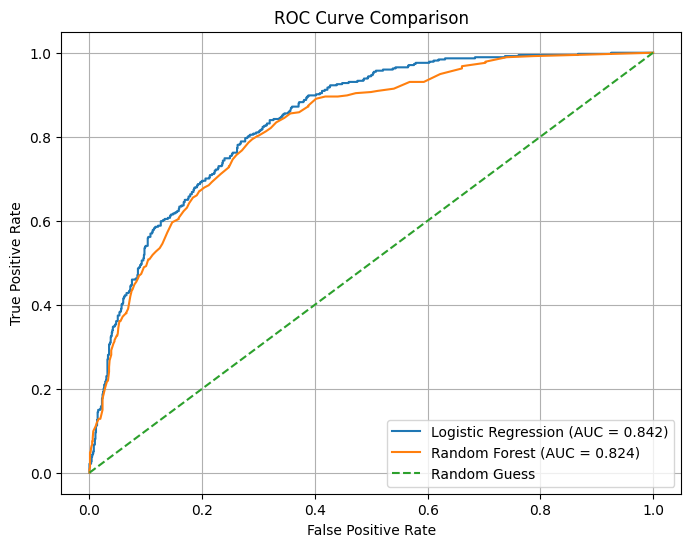

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve for Logistic Regression
fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_test, y_prob_logistic
)

# Calculate ROC curve for Random Forest
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test, y_prob_rf
)

# Calculate ROC-AUC scores
auc_lr = roc_auc_score(y_test, y_prob_logistic)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# Plot both ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr, tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.3f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

# Reference line for random guessing
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

### Interpretation of ROC Curve Comparison

The ROC curves were plotted to compare the ability of Logistic Regression and Random Forest to distinguish between customers who churn and those who do not.

Logistic Regression achieved a ROC-AUC score of 0.842, while Random Forest achieved 0.824. Both models performed considerably better than random guessing, represented by the diagonal reference line with an AUC of 0.500.

The Logistic Regression curve is generally closer to the top-left corner and slightly above the Random Forest curve. This indicates that Logistic Regression has a better ability to distinguish between churn and non-churn customers across different classification thresholds.

Overall, the ROC curve comparison supports the earlier evaluation and cross-validation results, suggesting that Logistic Regression is the stronger of the two models in this experiment.

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predictions using the default threshold of 0.5
y_pred_05 = (y_prob_logistic >= 0.5).astype(int)

# Predictions using a lower threshold of 0.3
y_pred_03 = (y_prob_logistic >= 0.3).astype(int)

# Calculate metrics for threshold 0.5
print("THRESHOLD 0.5")
print("Precision:", precision_score(y_test, y_pred_05))
print("Recall:", recall_score(y_test, y_pred_05))
print("F1 Score:", f1_score(y_test, y_pred_05))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_05))

# Calculate metrics for threshold 0.3
print("\nTHRESHOLD 0.3")
print("Precision:", precision_score(y_test, y_pred_03))
print("Recall:", recall_score(y_test, y_pred_03))
print("F1 Score:", f1_score(y_test, y_pred_03))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_03))

THRESHOLD 0.5
Precision: 0.6593059936908517
Recall: 0.5588235294117647
F1 Score: 0.6049204052098408
Confusion Matrix:
[[927 108]
 [165 209]]

THRESHOLD 0.3
Precision: 0.5202205882352942
Recall: 0.7566844919786097
F1 Score: 0.616557734204793
Confusion Matrix:
[[774 261]
 [ 91 283]]


### Classification Threshold Comparison

The Logistic Regression model was evaluated using two classification thresholds: 0.5 and 0.3.

At the default threshold of 0.5, the model achieved a precision of 65.93%, recall of 55.88%, and F1 score of 60.49%. It correctly identified 209 customers who churned but missed 165 actual churn cases.

When the threshold was reduced to 0.3, precision decreased to 52.02%, while recall increased to 75.67%. The F1 score also increased slightly to 61.66%. The number of false negatives decreased from 165 to 91, meaning the model identified 74 additional customers who actually churned.

However, false positives increased from 108 to 261. This means more customers who would have stayed were incorrectly classified as potential churners.

The results demonstrate a trade-off between precision and recall. A lower threshold may be useful for customer retention because it identifies more customers at risk of leaving, although it may also increase the cost of unnecessary retention campaigns.

Therefore, threshold selection should depend on the business objective and the relative costs of false positives and false negatives.

## Business Recommendations

Based on the exploratory data analysis and machine learning results, the following strategies are recommended to help reduce customer churn:

1. **Encourage longer-term contracts:** Customers with month-to-month contracts had a churn rate of 42.71%, compared with 2.83% for customers with two-year contracts. The company should consider offering loyalty rewards, discounts and additional benefits to encourage longer-term subscriptions.

2. **Improve customer onboarding:** Customers who churned had a median tenure of 10 months, compared with 38 months for customers who remained. The company should strengthen its onboarding process and provide regular support during the early stages of the customer relationship.

3. **Investigate fiber-optic service satisfaction:** Fiber-optic internet was strongly associated with higher predicted churn in the Logistic Regression model. The company should investigate service reliability, pricing, installation experiences and customer complaints among fiber-optic subscribers.

4. **Review pricing and billing practices:** Customers who churned had higher median monthly charges than those who stayed. The company should review its pricing structure, improve billing transparency and provide suitable subscription options.

5. **Promote technical support and online security services:** These services were associated with lower predicted churn in the Logistic Regression model. The company should improve their accessibility and consider offering them as part of customer retention packages.

The company could also use the Logistic Regression model to identify customers at risk of leaving and prioritise retention campaigns. The classification threshold should be selected based on the company's retention objectives and the costs of false positive and false negative predictions.

These recommendations are based on statistical associations and model predictions. Their actual effectiveness should be evaluated through customer feedback and controlled retention experiments.

## Limitations of the Project

Despite the useful findings obtained from the analysis, the project has some limitations.

1. **Dataset limitations:** The IBM Telco Customer Churn dataset contains 7,043 customer records and may not represent the behaviour of customers across all telecommunications companies or regions. It also lacks some potentially useful information, such as detailed customer complaints, network outages and competitors' offers.

2. **Model performance:** Although Logistic Regression achieved an accuracy of 80.62% and ROC-AUC of 84.22%, its recall at the default threshold of 0.5 was 55.88%. This means the model failed to identify 165 customers who actually churned.

3. **Class imbalance:** Approximately 73.46% of the customers did not churn, while 26.54% churned. This imbalance may affect the model's ability to identify customers in the minority churn class.

4. **Correlation versus causation:** The relationships identified between customer characteristics and churn do not establish cause and effect. For example, the association between fiber-optic internet and higher predicted churn does not prove that fiber-optic service causes customers to leave.

5. **Model limitations:** Logistic Regression may not capture every complex relationship in the data, while Random Forest feature importance does not explain the direction of a feature's relationship with churn. Model performance may also change when applied to new customer populations.

6. **Threshold selection:** The classification threshold affects the balance between precision and recall. A threshold suitable for one retention strategy may not be suitable for another.

7. **Production limitations:** The models were developed and evaluated using a sample dataset. They have not been validated using live customer data and should not be treated as fully reliable production systems without further testing.

Despite these limitations, the project demonstrates how machine learning can support customer churn analysis and help telecommunications companies identify customers who may be at risk of leaving.

## Conclusion

This project focused on developing a machine learning system to predict customer churn in the telecommunications industry using the IBM Telco Customer Churn dataset, which contains 7,043 customer records.

The project involved data inspection, cleaning, exploratory data analysis, feature engineering, preprocessing and model development. Two machine learning algorithms, Logistic Regression and Random Forest, were trained and evaluated.

The exploratory data analysis revealed that approximately 26.54% of customers had churned. Customers with month-to-month contracts recorded the highest churn rate of 42.71%, while those with two-year contracts had a much lower churn rate of 2.83%. The analysis also showed that customers who churned generally had shorter tenures and higher monthly charges.

Five-fold cross-validation showed that Logistic Regression performed better than Random Forest across all five evaluation metrics. Logistic Regression achieved an average cross-validation accuracy of 80.42% and ROC-AUC of 84.57%, compared with 78.61% accuracy and 82.53% ROC-AUC for Random Forest.

The Logistic Regression model also achieved a test-set accuracy of 80.62% and ROC-AUC of 84.22%. Further analysis of its coefficients and odds ratios identified fiber-optic internet, contract type, customer tenure and payment method as important features associated with churn predictions.

Classification threshold analysis demonstrated that reducing the threshold from 0.5 to 0.3 increased recall from 55.88% to 75.67%, although precision decreased from 65.93% to 52.02%. This highlighted the trade-off between identifying more potential churners and making additional incorrect churn predictions.

Overall, the project demonstrates how machine learning can help telecommunications companies identify customers who may be at risk of leaving. The findings can support targeted customer retention strategies, improve customer engagement and inform business decisions. However, further validation using real-world customer data would be necessary before deploying the system in a production environment.